# 02 · Análisis exploratorio del clima
## Estaciones SENAMHI de Cajamarca y su relación con la leishmaniosis cutánea, 2000–2024

**Fuente:** Servicio Nacional de Meteorología e Hidrología del Perú (SENAMHI), series diarias de precipitación y temperatura máxima/mínima en formato RClimDex. El valor `-99.9` marca un dato faltante.

**Objetivo:** decidir si el clima se puede usar como variable predictora en Cajamarca y con qué límites. Se revisa la calidad de las series, su cobertura en el tiempo, cómo se reparte entre estaciones, su estacionalidad y su relación con los casos.

**Alcance:** el proyecto se limita a Cajamarca (ver `PIPELINE_PROPUESTO.md`). Las 8 estaciones de Cusco que están en `data/raw/clima/` se describen solo para justificar que quedan fuera.

## 1. Inicializar e importar

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import stats

import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append("../src")
import integracion_clima as ic          # lectura de estaciones, clima mensual y match con los distritos
import preprocessing as pp

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12,
                     "figure.figsize": (12, 5)})
pd.options.display.float_format = "{:,.2f}".format

CLIMA = Path("../data/raw/clima")
EXTERNAL = Path("../data/raw/external")
RAW = Path("../data/raw/datos_abiertos_vigilancia_leishmaniosis_2000_2024.csv")
PROC = Path("../data/processed")
PLOTS = Path("../results/plots")
PLOTS.mkdir(parents=True, exist_ok=True)

REGION = ic.REGION                       # "CAJAMARCA"
AZUL, NARANJA, GRIS = "#2a6f97", "#e07a1f", "#8d99ae"

## 2. Carga de los archivos

Hay un `.txt` por estación, con una fila por día y las columnas año, mes, día, precipitación (mm), temperatura máxima y mínima (°C). Las coordenadas de cada estación están en `data/raw/external/estaciones_senamhi.csv`.

In [2]:
est = pd.read_csv(EXTERNAL / "estaciones_senamhi.csv")
archivos = sorted(CLIMA.glob("*/*.txt"))
print(f"{len(archivos)} archivos de estación")
print(est.groupby("region").size().rename("estaciones").to_string())

# Formato original del archivo
cols = ["anio", "mes", "dia", "pp", "tmax", "tmin"]
pd.read_csv(archivos[0], sep=r"\s+", header=None, usecols=range(6), names=cols).head()

34 archivos de estación
region
CAJAMARCA    26
CUSCO         8


,anio,mes,dia,pp,tmax,tmin
0,1964,12,1,0.00,-99.90,13.90
1,1964,12,2,0.01,-99.90,12.20
2,1964,12,3,0.01,-99.90,13.60
3,1964,12,4,0.00,-99.90,12.60
4,1964,12,5,0.00,-99.90,18.80


### 2.1 Lectura cruda y datos inválidos

Antes de limpiar se cuenta cada tipo de dato inválido, tal como viene en los archivos. La función `leer_estacion` de `src/integracion_clima.py` los convierte en nulos.

In [3]:
def leer_crudo(path):
    df = pd.read_csv(path, sep=r"\s+", header=None, usecols=range(6), names=cols)
    df["region"] = path.parent.name.upper()
    df["estacion"] = path.stem.split(" - ", 1)[-1].strip().upper()
    return df

crudo = pd.concat([leer_crudo(p) for p in archivos], ignore_index=True)

def resumen_invalidos(g):
    pp, tx, tn = g["pp"], g["tmax"], g["tmin"]
    ok_t = (tx > -99) & (tn > -99)
    return pd.Series({
        "días": len(g),
        "pp = -99.9": (pp <= -99).sum(),
        "tmax = -99.9": (tx <= -99).sum(),
        "tmin = -99.9": (tn <= -99).sum(),
        "pp negativa (≠ -99.9)": ((pp < 0) & (pp > -99)).sum(),
        "tmax < tmin": (ok_t & (tx < tn)).sum(),
    })

inv = crudo.groupby("region").apply(resumen_invalidos).astype(int)
pct = (inv.drop(columns="días").div(inv["días"], axis=0) * 100).add_suffix(" (%)")
display(inv.T)                 # conteos
pct.round(2).T                 # porcentaje sobre el total de días de la región

region,CAJAMARCA,CUSCO
días,458781,139717
pp = -99.9,19078,9440
tmax = -99.9,227963,48187
tmin = -99.9,228390,49786
pp negativa (≠ -99.9),0,0
tmax < tmin,0,0


region,CAJAMARCA,CUSCO
pp = -99.9 (%),4.16,6.76
tmax = -99.9 (%),49.69,34.49
tmin = -99.9 (%),49.78,35.63
pp negativa (≠ -99.9) (%),0.00,0.00
tmax < tmin (%),0.00,0.00


In [4]:
# Filas con fecha imposible o repetida (leer_estacion las descarta)
f = pd.to_datetime(crudo[["anio", "mes", "dia"]].rename(columns={"anio": "year", "mes": "month", "dia": "day"}),
                   errors="coerce")
print("Fechas inválidas:", f.isna().sum())
print("Fechas repetidas dentro de una estación:",
      pd.DataFrame({"estacion": crudo["estacion"], "f": f}).dropna().duplicated().sum())

Fechas inválidas: 0
Fechas repetidas dentro de una estación: 0


In [5]:
diario = ic.clima_diario(CLIMA, est)         # todos los inválidos -> NaN
c = diario[diario["region"] == REGION].copy()
c["anio"] = c["fecha"].dt.year
c["tmed"] = (c["tmax"] + c["tmin"]) / 2
print(f"Cajamarca: {len(c):,} días-estación, {c['codigo'].nunique()} estaciones, "
      f"{c['fecha'].min():%Y-%m-%d} a {c['fecha'].max():%Y-%m-%d}")

Cajamarca: 458,781 días-estación, 26 estaciones, 1933-10-01 a 2015-10-31


**Qué muestran los datos crudos.** Cajamarca aporta 26 estaciones y 458 781 días-estación (de 1933 a 2015). No hay precipitaciones negativas, ni días con temperatura máxima menor que la mínima, ni fechas inválidas o repetidas: el único dato inválido es el código `-99.9`. La precipitación tiene 4,2 % de faltantes, pero **la temperatura casi la mitad** (49,7 % en la máxima y 49,8 % en la mínima), frente a 34–36 % en Cusco.

## 3. Calidad por estación

In [6]:
resumen = (c.groupby("estacion")
           .agg(inicio=("fecha", "min"), fin=("fecha", "max"), dias=("fecha", "size"),
                pp_falt=("pp", lambda s: s.isna().mean() * 100),
                tmax_falt=("tmax", lambda s: s.isna().mean() * 100),
                tmin_falt=("tmin", lambda s: s.isna().mean() * 100))
           .sort_values("fin"))
resumen["inicio"] = resumen["inicio"].dt.strftime("%Y-%m")
resumen["fin"] = resumen["fin"].dt.strftime("%Y-%m")
resumen.rename(columns={"pp_falt": "pp faltante (%)", "tmax_falt": "tmax faltante (%)",
                        "tmin_falt": "tmin faltante (%)"})

,inicio,fin,dias,pp faltante (%),tmax faltante (%),tmin faltante (%)
estacion,,,,,,
CACHACHI,1963-01,2014-02,18687,4.24,100.00,100.00
CHUGUR,1963-09,2014-02,18444,1.01,100.00,100.00
CILETE,1963-09,2014-02,18444,3.84,100.00,100.00
LIVES,1963-09,2014-02,18444,0.17,100.00,100.00
ASUNCION,1963-09,2014-06,18566,4.26,53.83,51.13
TABACONAS,1964-12,2014-06,18109,2.22,2.76,6.70
CAJABAMBA,1963-10,2014-06,18536,10.82,12.69,12.52
SAN MARCOS,1963-03,2014-06,18750,1.66,6.17,7.88
SAN BENITO,1963-09,2014-06,18566,1.31,77.26,73.75


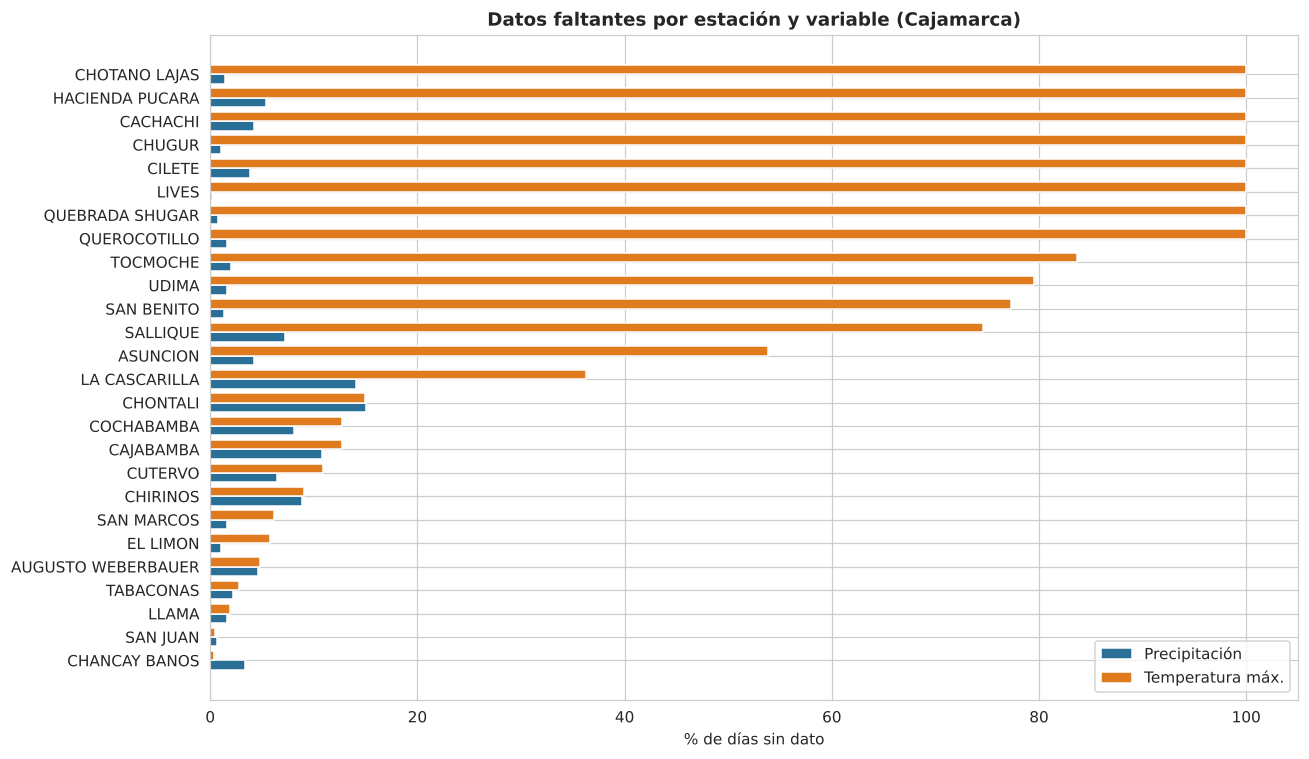

In [7]:
fig, ax = plt.subplots(figsize=(12, 7))
orden = resumen.sort_values("tmax_falt").index
y = np.arange(len(orden))
ax.barh(y - 0.2, resumen.loc[orden, "pp_falt"], 0.4, color=AZUL, label="Precipitación")
ax.barh(y + 0.2, resumen.loc[orden, "tmax_falt"], 0.4, color=NARANJA, label="Temperatura máx.")
ax.set_yticks(y); ax.set_yticklabels(orden)
ax.set_xlabel("% de días sin dato"); ax.set_title("Datos faltantes por estación y variable (Cajamarca)")
ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig(PLOTS / "eda_clima_faltantes.png", bbox_inches="tight"); plt.show()

### 3.1 Estaciones con y sin temperatura

Una estación "tiene temperatura" si cubre al menos el 50 % de los meses desde 2000 (`MIN_MESES_TEMP`). Es el criterio que usa `integracion_clima.py` para asignar la temperatura a cada distrito.

In [8]:
mensual = ic.clima_mensual(diario)                    # promedios mensuales; mes válido si >= 80 % de días
estaciones = ic.resumen_estaciones(mensual)
print(estaciones["tiene_temp"].value_counts().rename({True: "con temperatura", False: "sin temperatura"}).to_string())
print("\nSin temperatura:", ", ".join(estaciones.loc[~estaciones["tiene_temp"], "estacion"]))

tiene_temp
con temperatura    18
sin temperatura     8

Sin temperatura: HACIENDA PUCARA, QUEBRADA SHUGAR, QUEROCOTILLO, LIVES, CILETE, CHUGUR, CACHACHI, CHOTANO LAJAS


### 3.2 Valores extremos
Solo se detectan y se describen. No se recorta nada: la lluvia intensa y las temperaturas extremas son parte de la señal.

In [9]:
print(c[["pp", "tmax", "tmin"]].describe().round(2).to_string())
print("\nDías con lluvia (pp > 0):", f"{(c['pp'] > 0).mean():.1%} de los días con dato")
print("\nLos 8 días más lluviosos:")
c.nlargest(8, "pp")[["estacion", "fecha", "pp"]].reset_index(drop=True)

              pp       tmax       tmin
count 439,703.00 230,818.00 230,391.00
mean        2.27      23.20      12.28
std         6.02       3.85       3.75
min         0.00       9.60      -4.30
25%         0.00      20.50      10.20
50%         0.00      22.80      12.20
75%         1.50      25.50      14.50
max       540.00      39.80      25.60

Días con lluvia (pp > 0): 32.9% de los días con dato

Los 8 días más lluviosos:


,estacion,fecha,pp
0,UDIMA,2000-03-08,540.00
1,CACHACHI,1967-02-19,260.60
2,CACHACHI,1967-03-16,255.10
3,UDIMA,2000-03-29,230.00
4,CACHACHI,1967-03-03,205.20
5,CACHACHI,1969-04-23,200.00
6,CACHACHI,1969-04-09,190.50
7,CACHACHI,1969-04-16,190.00


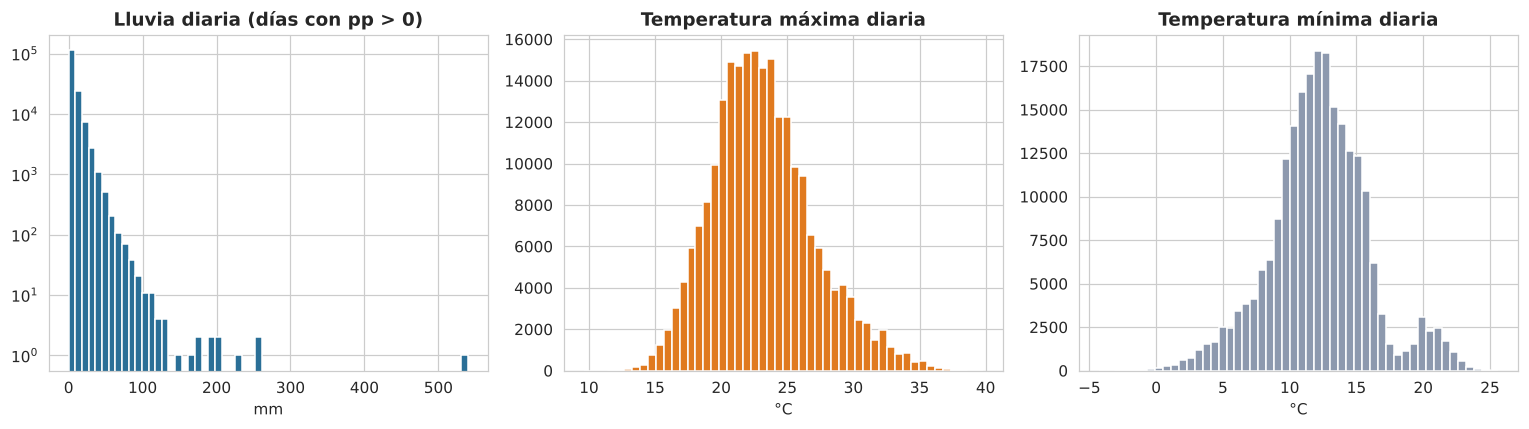

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
ax[0].hist(c.loc[c["pp"] > 0, "pp"].dropna(), bins=60, color=AZUL); ax[0].set_yscale("log")
ax[0].set_title("Lluvia diaria (días con pp > 0)"); ax[0].set_xlabel("mm")
ax[1].hist(c["tmax"].dropna(), bins=50, color=NARANJA); ax[1].set_title("Temperatura máxima diaria"); ax[1].set_xlabel("°C")
ax[2].hist(c["tmin"].dropna(), bins=50, color=GRIS); ax[2].set_title("Temperatura mínima diaria"); ax[2].set_xlabel("°C")
plt.tight_layout(); plt.savefig(PLOTS / "eda_clima_distribuciones.png", bbox_inches="tight"); plt.show()

**Hallazgos de calidad**

- **8 de las 26 estaciones no tienen ningún dato de temperatura** (Cachachi, Chugur, Cilete, Lives, Chotano Lajas, Querocotillo, Quebrada Shugar y Hacienda Pucará). Otras cuatro (San Benito, Tocmoche, Sallique y Asunción) tienen entre 54 % y 84 % de días sin temperatura máxima.
- La lluvia está casi completa: en 24 de las 26 estaciones faltan menos del 11 % de los días. Las peores son Chontalí (15 %) y La Cascarilla (14 %).
- Las temperaturas son plausibles (máxima entre 9,6 y 39,8 °C, mínima entre −4,3 y 25,6 °C). La lluvia diaria tiene la cola larga esperada: llueve en el 33 % de los días con dato y el máximo es **540 mm en un solo día** (Udima, 8 de marzo de 2000). Es más del doble del siguiente valor más alto desde 2000 (230 mm, también en Udima) y conviene verificarlo con SENAMHI; por ahora no se corrige, igual que los picos de casos.

## 4. Cobertura en el tiempo

Lo decisivo para modelar: **¿hay clima en el periodo de entrenamiento (hasta 2018) y en el de prueba (2019–2024)?**

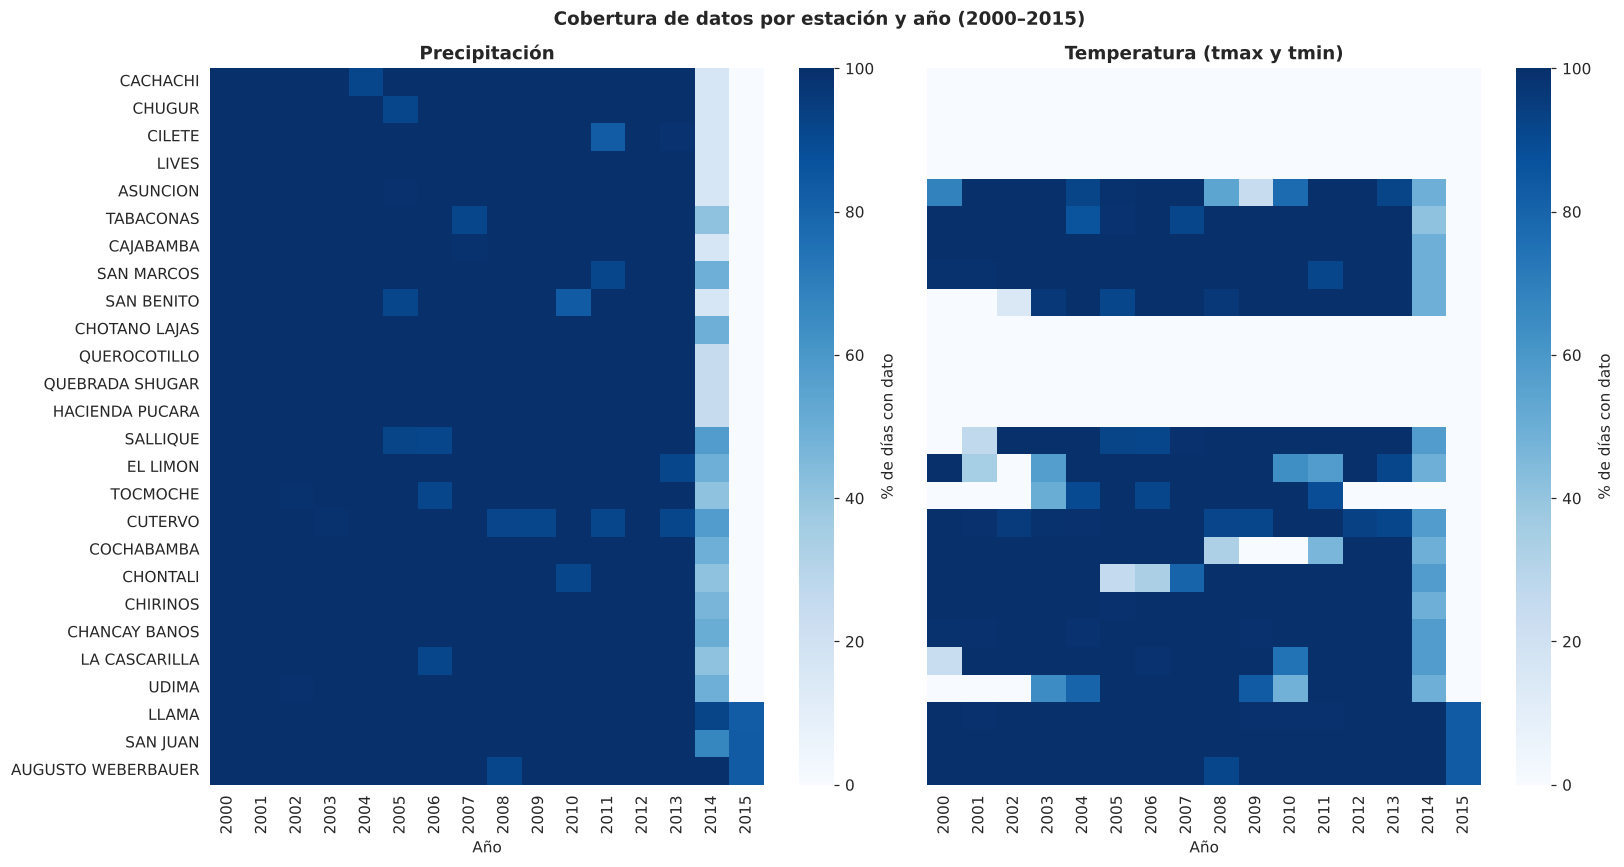

In [11]:
dias_anio = lambda a: 365 + ((a % 4 == 0) & ((a % 100 != 0) | (a % 400 == 0)))
cob = c.groupby(["estacion", "anio"]).agg(pp=("pp", "count"), t=("tmed", "count"))
cob = cob.div(dias_anio(cob.index.get_level_values("anio")), axis=0) * 100

orden = resumen.index          # ordenado por fecha de fin
fig, ax = plt.subplots(1, 2, figsize=(15, 8), sharey=True)
for a, col, titulo in zip(ax, ["pp", "t"], ["Precipitación", "Temperatura (tmax y tmin)"]):
    hm = cob[col].unstack("anio").reindex(index=orden, columns=range(2000, 2016)).fillna(0)
    sns.heatmap(hm, ax=a, cmap="Blues", vmin=0, vmax=100, cbar_kws={"label": "% de días con dato"})
    a.set_title(titulo); a.set_xlabel("Año"); a.set_ylabel("")
plt.suptitle("Cobertura de datos por estación y año (2000–2015)", fontweight="bold")
plt.tight_layout(); plt.savefig(PLOTS / "eda_clima_cobertura.png", bbox_inches="tight"); plt.show()

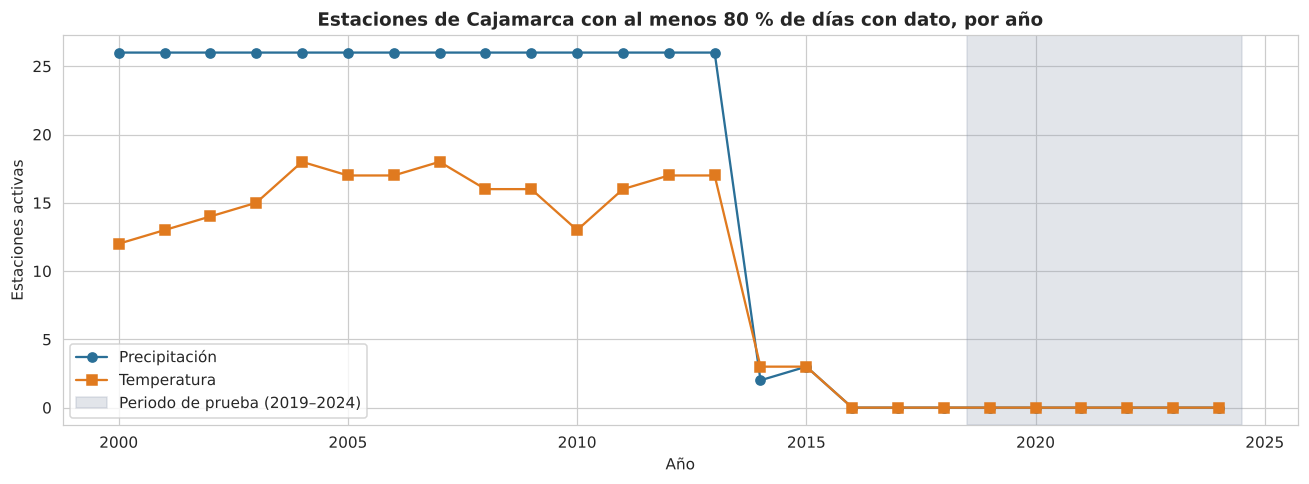

anio,2000,2005,2010,2013,2014,2015,2016,2019,2024
Precipitación,26,26,26,26,2,3,0,0,0
Temperatura,12,17,13,17,3,3,0,0,0


In [12]:
# Estaciones activas por año (>= 80 % de días con dato, el mismo criterio de un mes válido)
act = pd.DataFrame({
    "Precipitación": (cob["pp"] >= 80).groupby("anio").sum(),
    "Temperatura": (cob["t"] >= 80).groupby("anio").sum(),
}).reindex(range(2000, 2025), fill_value=0)

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(act.index, act["Precipitación"], marker="o", color=AZUL, label="Precipitación")
ax.plot(act.index, act["Temperatura"], marker="s", color=NARANJA, label="Temperatura")
ax.axvspan(2018.5, 2024.5, color=GRIS, alpha=0.25, label="Periodo de prueba (2019–2024)")
ax.set_xlabel("Año"); ax.set_ylabel("Estaciones activas")
ax.set_title("Estaciones de Cajamarca con al menos 80 % de días con dato, por año")
ax.legend(); plt.tight_layout(); plt.savefig(PLOTS / "eda_clima_estaciones_activas.png", bbox_inches="tight"); plt.show()
act.loc[[2000, 2005, 2010, 2013, 2014, 2015, 2016, 2019, 2024]].T

**Qué muestra la cobertura.** Es el hallazgo más importante del notebook.

- Entre 2000 y 2013 las 26 estaciones tienen lluvia casi completa. La temperatura es más irregular: hay entre 12 y 18 estaciones con datos según el año.
- **Las series se cortan en 2014.** La mayoría termina entre febrero y julio de ese año, así que 2014 queda con datos parciales (solo 2 estaciones superan el 80 % de días). Únicamente Llama, San Juan y Augusto Weberbauer llegan hasta octubre de 2015.
- **De 2016 a 2024 no hay ninguna estación.** Eso deja sin clima no solo el periodo de prueba (2019–2024), sino también 2015–2018 dentro del de entrenamiento.

### 4.1 Comparación con las estaciones de Cusco

Se muestra solo para justificar que quedan fuera del alcance.

In [13]:
cu = diario[diario["region"] == "CUSCO"]
print(f"Cusco: {cu['codigo'].nunique()} estaciones, {cu['fecha'].min():%Y-%m} a {cu['fecha'].max():%Y-%m}")
cu.groupby("estacion")["fecha"].agg(["min", "max"]).assign(
    min=lambda d: d["min"].dt.strftime("%Y-%m"), max=lambda d: d["max"].dt.strftime("%Y-%m")
).rename(columns={"min": "inicio", "max": "fin"}).sort_values("fin")

Cusco: 8 estaciones, 1963-12 a 2015-10


,inicio,fin
estacion,,
ACOMAYO,1963-12,2014-06
CAYCAY,1964-12,2014-06
CCATCCA,1965-01,2014-06
COLQUEPATA,1964-01,2014-06
PARURO,1964-01,2014-06
PISAC,1963-12,2014-06
POMACANCHI,1985-01,2014-06
GRANJA KCAYRA,1964-01,2015-10


Las estaciones de Cusco tienen el mismo problema (terminan en junio de 2014, salvo Granja Kcayra en octubre de 2015) y además están fuera del alcance. Como `PIPELINE_PROPUESTO.md` indica, no se usan.

## 5. Las estaciones no son homogéneas

Cada distrito toma el clima de su estación más cercana. Eso solo tiene sentido si las estaciones realmente difieren, y si están razonablemente cerca de donde ocurren los casos.

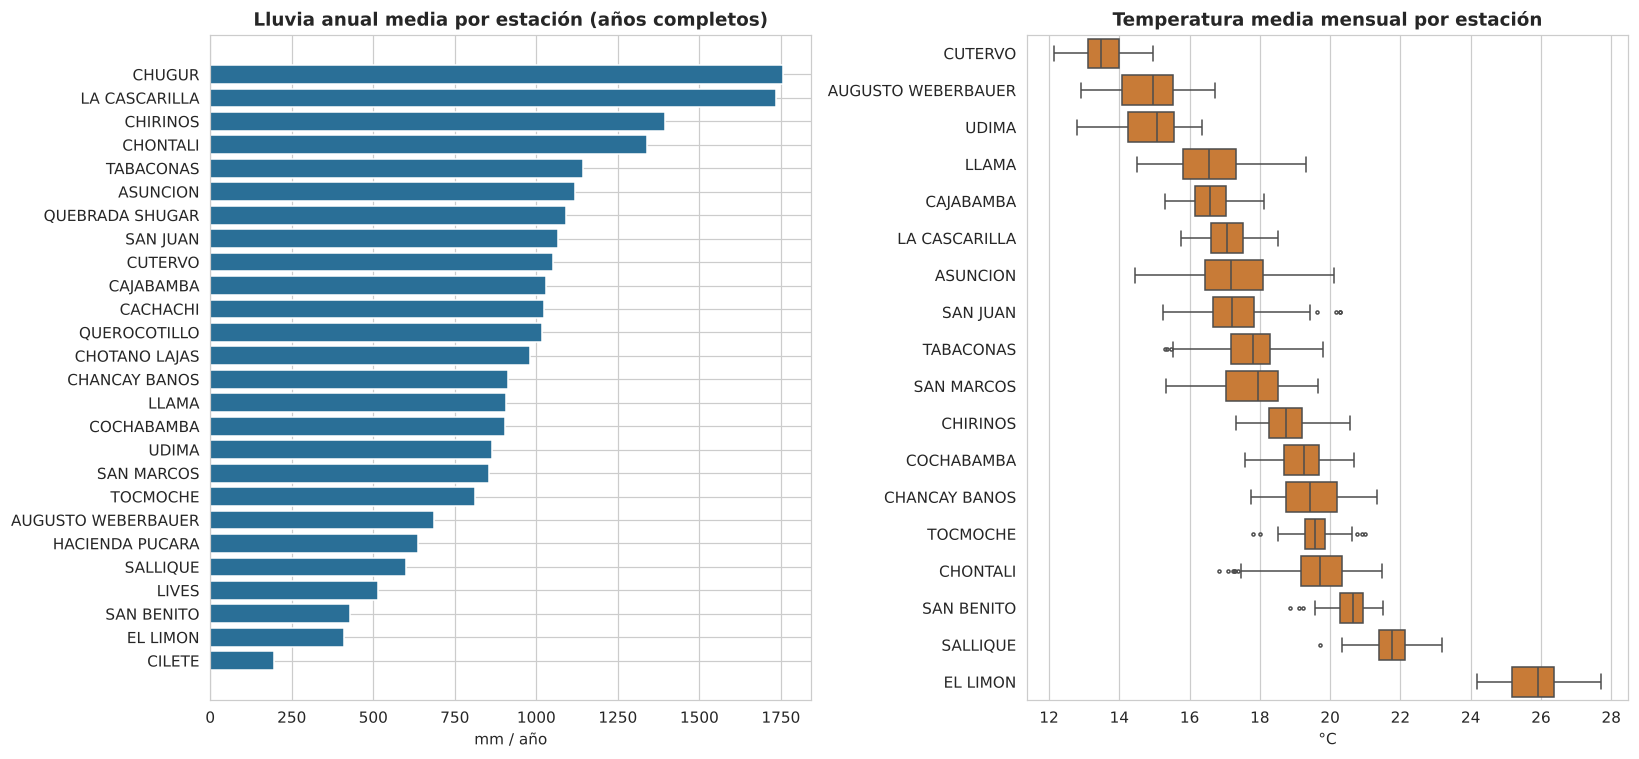

Lluvia anual: de 195 a 1,755 mm  |  temperatura mediana: de 13.5 a 25.9 °C


In [14]:
m = mensual[(mensual["fecha_mes"] >= "2001-01-01") & (mensual["fecha_mes"] < "2015-01-01")].merge(
    estaciones[["codigo", "tiene_temp"]], on="codigo")

fig, ax = plt.subplots(1, 2, figsize=(15, 7))
anual = (m.groupby(["estacion", m["fecha_mes"].dt.year])["pp_total_mm"].sum(min_count=12)
         .groupby("estacion").mean().sort_values())
ax[0].barh(anual.index, anual.values, color=AZUL)
ax[0].set_title("Lluvia anual media por estación (años completos)"); ax[0].set_xlabel("mm / año")

mt = m[m["tiene_temp"]].dropna(subset=["tmed_media"])
orden_t = mt.groupby("estacion")["tmed_media"].median().sort_values().index
sns.boxplot(data=mt, y="estacion", x="tmed_media", order=orden_t, color=NARANJA, fliersize=2, ax=ax[1])
ax[1].set_title("Temperatura media mensual por estación"); ax[1].set_xlabel("°C"); ax[1].set_ylabel("")
plt.tight_layout(); plt.savefig(PLOTS / "eda_clima_heterogeneidad.png", bbox_inches="tight"); plt.show()
print(f"Lluvia anual: de {anual.min():,.0f} a {anual.max():,.0f} mm  |  "
      f"temperatura mediana: de {mt.groupby('estacion')['tmed_media'].median().min():.1f} a "
      f"{mt.groupby('estacion')['tmed_media'].median().max():.1f} °C")

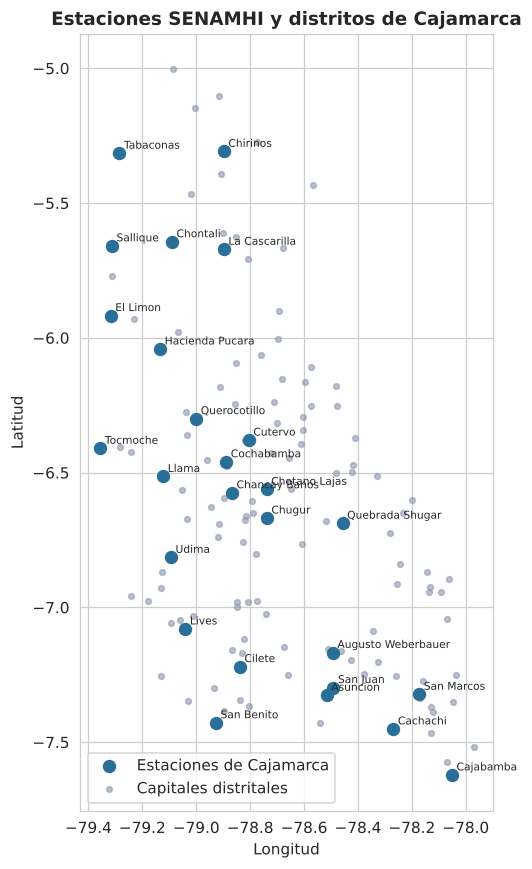

In [15]:
fig, ax = plt.subplots(figsize=(8, 8))
cu_est = est[est["region"] == "CUSCO"]
ca_est = est[est["region"] == REGION]
ax.scatter(ca_est["longitud"], ca_est["latitud"], s=60, color=AZUL, label="Estaciones de Cajamarca", zorder=3)
dist = pd.read_csv(EXTERNAL / "distritos_cajamarca.csv")
ax.scatter(dist["longitude"], dist["latitude"], s=14, color=GRIS, alpha=0.6, label="Capitales distritales", zorder=2)
for _, r in ca_est.iterrows():
    ax.annotate(r["estacion"].title(), (r["longitud"], r["latitud"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set_xlabel("Longitud"); ax.set_ylabel("Latitud"); ax.set_aspect("equal")
ax.set_title("Estaciones SENAMHI y distritos de Cajamarca"); ax.legend(loc="lower left")
plt.tight_layout(); plt.savefig(PLOTS / "eda_clima_mapa.png", bbox_inches="tight"); plt.show()

**Las estaciones son muy distintas entre sí.** La lluvia anual media va de 195 a 1 755 mm y la temperatura mediana de 13,5 a 25,9 °C. Por eso importa a qué estación se asigna cada distrito: una estación equivocada no daría un clima parecido. El mapa muestra que la cobertura espacial es desigual: hay zonas con varios distritos y ninguna estación cerca, por ejemplo en el este y en el norte.

## 6. Estacionalidad del clima y de los casos

La climatología mensual (promedio de cada mes del año, 2001–2014) se compara con la estacionalidad de los casos del mismo periodo. La banda gris cubre del primer al tercer cuartil entre estaciones.

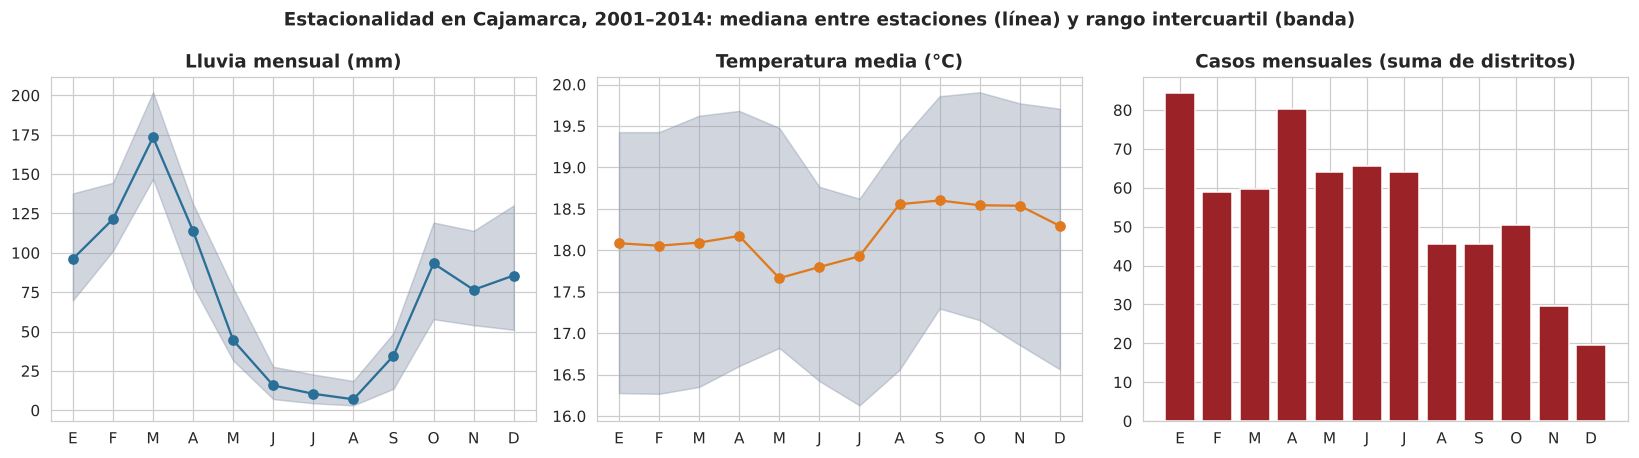

Mes con más lluvia (mediana): 3 | mes con menos: 8
Mes con más casos: 1 | mes con menos: 12


In [16]:
clim = (m.groupby(["codigo", m["fecha_mes"].dt.month])[["pp_total_mm", "tmed_media"]].mean()
        .rename_axis(["codigo", "mes"]).reset_index())
casos = pp.build_monthly_panel(pp.clean_cases(pp.load_raw(RAW)).query("departamento == @REGION"), drop_incomplete=False)
casos = casos[(casos["fecha_mes"] >= "2001-01-01") & (casos["fecha_mes"] < "2015-01-01")]
cas_mes = casos.groupby([casos["fecha_mes"].dt.year, casos["fecha_mes"].dt.month])["casos"].sum().groupby(level=1)
cas_mes = cas_mes.mean()

meses = ["E", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"]
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
for a, var, ttl, col in [(ax[0], "pp_total_mm", "Lluvia mensual (mm)", AZUL),
                         (ax[1], "tmed_media", "Temperatura media (°C)", NARANJA)]:
    g = clim.groupby("mes")[var]
    a.fill_between(range(1, 13), g.quantile(0.25), g.quantile(0.75), color=GRIS, alpha=0.4)
    a.plot(range(1, 13), g.median(), marker="o", color=col)
    a.set_title(ttl); a.set_xticks(range(1, 13)); a.set_xticklabels(meses)
ax[2].bar(range(1, 13), cas_mes.values, color="#9b2226")
ax[2].set_title("Casos mensuales (suma de distritos)"); ax[2].set_xticks(range(1, 13)); ax[2].set_xticklabels(meses)
plt.suptitle("Estacionalidad en Cajamarca, 2001–2014: mediana entre estaciones (línea) y rango intercuartil (banda)", fontweight="bold")
plt.tight_layout(); plt.savefig(PLOTS / "eda_clima_estacionalidad.png", bbox_inches="tight"); plt.show()
print("Mes con más lluvia (mediana):", int(clim.groupby("mes")["pp_total_mm"].median().idxmax()),
      "| mes con menos:", int(clim.groupby("mes")["pp_total_mm"].median().idxmin()))
print("Mes con más casos:", int(cas_mes.idxmax()), "| mes con menos:", int(cas_mes.idxmin()))

**Los ciclos de lluvia y de casos no coinciden con claridad.** La lluvia tiene un máximo marcado en marzo (mediana de unos 173 mm) y un mínimo en agosto (unos 7 mm). La temperatura casi no varía a lo largo del año (las medianas oscilan entre 17,7 y 18,6 °C), aunque entre estaciones la diferencia es grande. Los casos son más altos de enero a julio y mínimos en noviembre y diciembre. El pico de enero se debe en parte a la anomalía de la semana 1 que ya se documentó en `01_eda.ipynb`.

## 7. Integración con los casos

`integracion_clima.py` asigna a cada distrito la estación más cercana a las localidades donde se concentran sus casos de entrenamiento, y une su clima mensual (con rezagos de 1 a 3 meses) al panel distrito × mes. El resultado es `dataset_cajamarca.csv`.

In [17]:
if not (PROC / "dataset_cajamarca.csv").exists():
    ic.run(RAW, CLIMA, PROC, external=EXTERNAL)
final = pd.read_csv(PROC / "dataset_cajamarca.csv", parse_dates=["fecha_mes"], dtype={"ubigeo": str})
final["tiene_temp"] = final["tmed_media"].notna()
print(f"Panel de Cajamarca: {len(final):,} filas, {final['ubigeo'].nunique()} distritos, "
      f"{final['fecha_mes'].min():%Y-%m} a {final['fecha_mes'].max():%Y-%m}")

cob_split = final.groupby("es_train").agg(filas=("casos", "size"),
                                          con_clima=("tiene_clima", "mean"),
                                          con_temperatura=("tiene_temp", "mean"))
cob_split.index = cob_split.index.map({True: "Entrenamiento (≤ 2018)", False: "Prueba (2019–2024)"})
cob_split

Panel de Cajamarca: 20,160 filas, 70 distritos, 2001-01 a 2024-12


,filas,con_clima,con_temperatura
es_train,,,
Prueba (2019–2024),5040,0.00,0.00
Entrenamiento (≤ 2018),15120,0.74,0.70


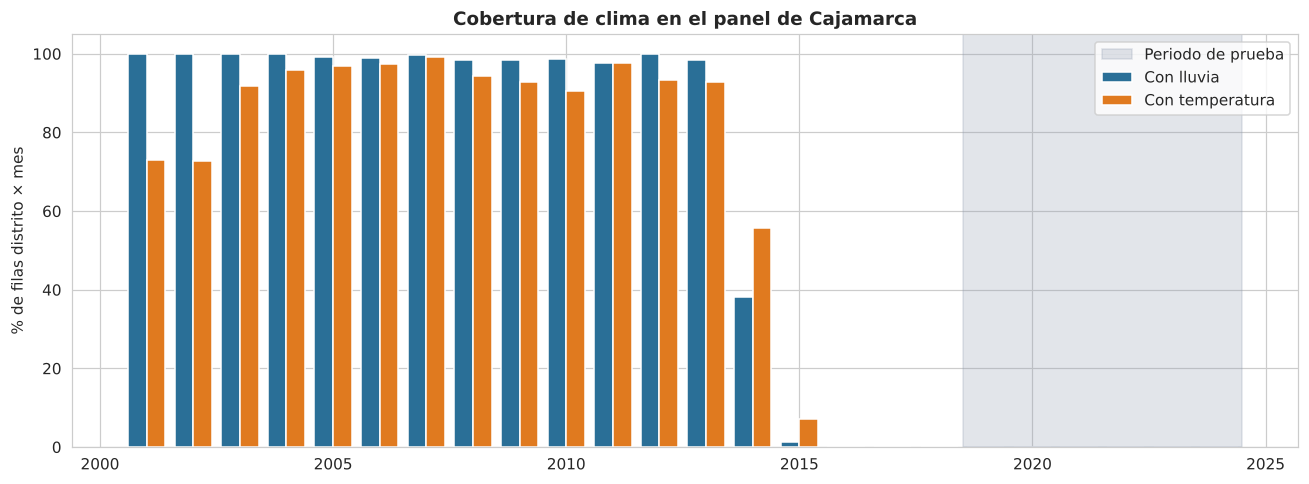

In [18]:
anual = final.groupby(final["fecha_mes"].dt.year)[["tiene_clima", "tiene_temp"]].mean() * 100
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.bar(anual.index - 0.2, anual["tiene_clima"], 0.4, color=AZUL, label="Con lluvia")
ax.bar(anual.index + 0.2, anual["tiene_temp"], 0.4, color=NARANJA, label="Con temperatura")
ax.axvspan(2018.5, 2024.5, color=GRIS, alpha=0.25, label="Periodo de prueba")
ax.set_ylabel("% de filas distrito × mes"); ax.set_title("Cobertura de clima en el panel de Cajamarca")
ax.legend(); plt.tight_layout(); plt.savefig(PLOTS / "eda_clima_cobertura_panel.png", bbox_inches="tight"); plt.show()

Distancia del distrito a su estación (km, ponderada por los casos de sus localidades):
       estación de lluvia  estación de temperatura
count               70.00                    70.00
mean                17.90                    23.30
std                 11.10                    14.90
min                  1.30                     1.30
25%                 10.50                    12.60
50%                 16.30                    19.80
75%                 23.30                    32.10
max                 45.60                    67.80

Distritos cuya estación concentra < 80 % de sus casos de entrenamiento: 17 de 70


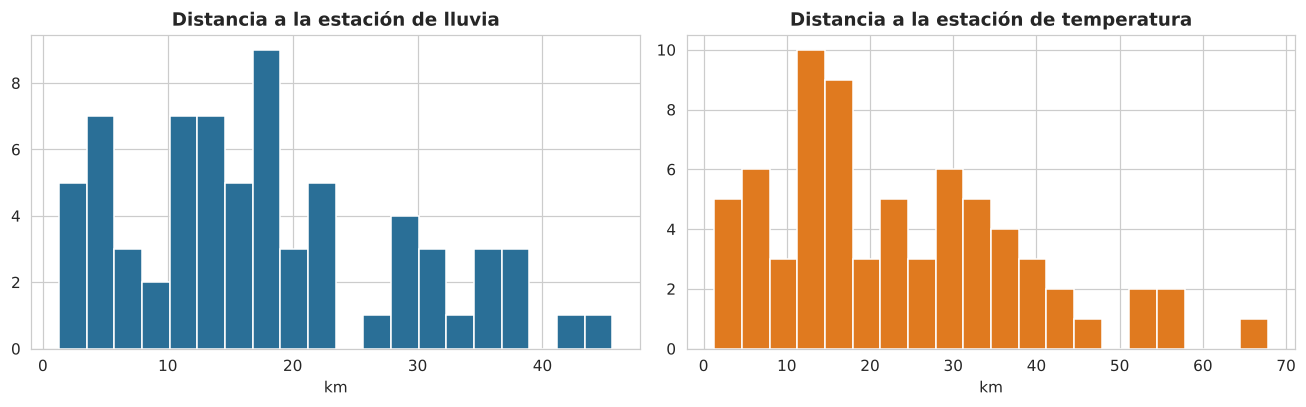

In [19]:
por_distrito = final.drop_duplicates("ubigeo")
print("Distancia del distrito a su estación (km, ponderada por los casos de sus localidades):")
print(por_distrito[["dist_pp_km", "dist_t_km"]].describe().round(1).rename(
    columns={"dist_pp_km": "estación de lluvia", "dist_t_km": "estación de temperatura"}).to_string())
print("\nDistritos cuya estación concentra < 80 % de sus casos de entrenamiento:",
      int((por_distrito["pct_casos_pp"] < 80).sum()), "de", len(por_distrito))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].hist(por_distrito["dist_pp_km"], bins=20, color=AZUL); ax[0].set_title("Distancia a la estación de lluvia"); ax[0].set_xlabel("km")
ax[1].hist(por_distrito["dist_t_km"], bins=20, color=NARANJA); ax[1].set_title("Distancia a la estación de temperatura"); ax[1].set_xlabel("km")
plt.tight_layout(); plt.savefig(PLOTS / "eda_clima_distancias.png", bbox_inches="tight"); plt.show()

**Qué cambia al llegar al panel.**

- **Entrenamiento:** 74 % de las filas distrito × mes tienen lluvia y 70 % tiene temperatura. Es menos de 100 % porque las series terminan en 2014 y el entrenamiento llega hasta 2018.
- **Prueba:** 0 %. El panel completo queda con clima en el 55 % de las filas.
- **Distancia:** la estación asignada está a una mediana de 16 km del distrito para lluvia y 20 km para temperatura, pero llega a 46 y 68 km. En 17 de los 70 distritos la estación elegida concentra menos del 80 % de sus casos de entrenamiento, así que sus localidades quedan más cerca de otra.

## 8. Relación del clima con los casos

Se mide con la correlación de Spearman entre los casos del distrito en el mes *t* y el clima del mes *t − k*, usando solo las filas con clima (todas de entrenamiento). Se usa Spearman porque los casos tienen muchos ceros y una cola larga.

Hay dos versiones:
- **Con estacionalidad:** los valores tal cual. Mezcla el efecto del clima con el simple hecho de que ambos tienen ciclo anual.
- **Sin estacionalidad (anomalías):** a cada valor se le resta el promedio de su distrito en ese mes del año. Mide si un mes más lluvioso o más cálido de lo normal se asocia con más o menos casos.

In [20]:
d = final[final["es_train"]].copy()
d["mes"] = d["fecha_mes"].dt.month

def correlaciones(var):
    filas = []
    for k in range(0, 4):
        col = var if k == 0 else f"{var}_lag{k}"
        s = d.dropna(subset=[col])
        x_an = s[col] - s.groupby(["ubigeo", "mes"])[col].transform("mean")
        y_an = s["casos"] - s.groupby(["ubigeo", "mes"])["casos"].transform("mean")
        filas.append({"variable": var, "rezago (meses)": k, "n": len(s),
                      "con estacionalidad": stats.spearmanr(s["casos"], s[col])[0],
                      "sin estacionalidad": stats.spearmanr(y_an, x_an)[0]})
    return pd.DataFrame(filas)

corr = pd.concat([correlaciones(v) for v in ["pp_total_mm", "tmed_media", "tmax_media", "tmin_media"]], ignore_index=True)
corr

,variable,rezago (meses),n,con estacionalidad,sin estacionalidad
0,pp_total_mm,0,11160,0.06,0.02
1,pp_total_mm,1,11229,0.07,0.00
2,pp_total_mm,2,11298,0.08,-0.01
3,pp_total_mm,3,11367,0.12,-0.02
4,tmed_media,0,10516,-0.01,0.00
5,tmed_media,1,10562,-0.01,0.02
6,tmed_media,2,10608,0.00,0.03
7,tmed_media,3,10654,0.02,0.03
8,tmax_media,0,10676,-0.05,-0.01
9,tmax_media,1,10722,-0.05,0.00


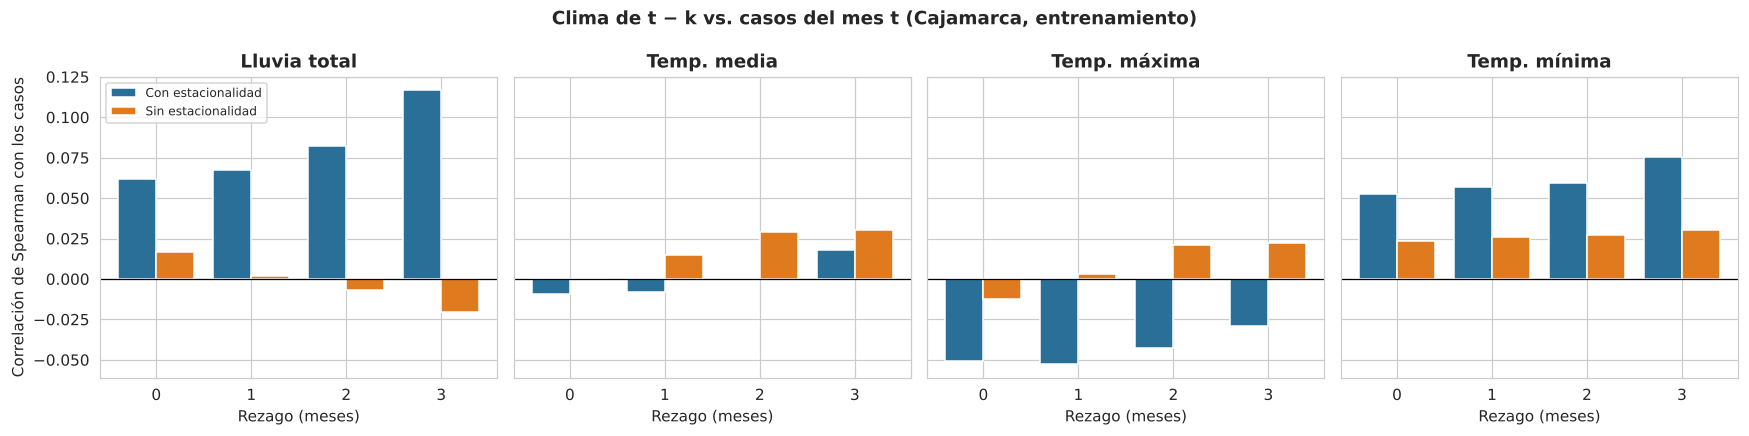

In [21]:
nombres = {"pp_total_mm": "Lluvia total", "tmed_media": "Temp. media", "tmax_media": "Temp. máxima", "tmin_media": "Temp. mínima"}
fig, ax = plt.subplots(1, 4, figsize=(16, 4), sharey=True)
for a, (var, g) in zip(ax, corr.groupby("variable", sort=False)):
    a.bar(g["rezago (meses)"] - 0.2, g["con estacionalidad"], 0.4, color=AZUL, label="Con estacionalidad")
    a.bar(g["rezago (meses)"] + 0.2, g["sin estacionalidad"], 0.4, color=NARANJA, label="Sin estacionalidad")
    a.axhline(0, color="black", lw=0.8); a.set_title(nombres[var]); a.set_xlabel("Rezago (meses)"); a.set_xticks(range(4))
ax[0].set_ylabel("Correlación de Spearman con los casos"); ax[0].legend(fontsize=8)
plt.suptitle("Clima de t − k vs. casos del mes t (Cajamarca, entrenamiento)", fontweight="bold")
plt.tight_layout(); plt.savefig(PLOTS / "eda_clima_correlaciones.png", bbox_inches="tight"); plt.show()

In [22]:
# ¿El clima aporta algo que no digan ya los casos pasados? Se ajusta una regresión lineal de los casos sobre
# lag1, lag12 y media3 (entrenamiento, filas con clima) y se correlaciona su residuo con las anomalías del clima.
from sklearn.linear_model import LinearRegression
filas = []
for col in ["pp_total_mm_lag1", "pp_total_mm_lag2", "pp_total_mm_lag3",
            "tmed_media_lag1", "tmed_media_lag2", "tmed_media_lag3"]:
    s = d.dropna(subset=[col]).copy()
    Xb = s[["lag1", "lag12", "media3"]].to_numpy()
    residuo = s["casos"].to_numpy() - LinearRegression().fit(Xb, s["casos"]).predict(Xb)
    x = s[col] - s.groupby(["ubigeo", "mes"])[col].transform("mean")
    filas.append({"clima": col, "n": len(s), "rho con el residuo": stats.spearmanr(residuo, x)[0]})
pd.DataFrame(filas)

,clima,n,rho con el residuo
0,pp_total_mm_lag1,11229,-0.02
1,pp_total_mm_lag2,11298,-0.03
2,pp_total_mm_lag3,11367,-0.03
3,tmed_media_lag1,10562,0.04
4,tmed_media_lag2,10608,0.04
5,tmed_media_lag3,10654,0.02


**Distrito × mes: la relación es muy débil.** Con estacionalidad, la correlación de Spearman es baja (máximo 0,12, con la lluvia de tres meses atrás) y casi desaparece al quitar el ciclo anual (|ρ| ≤ 0,03). Incluso frente a lo que los casos pasados no explican, el clima de los meses anteriores no tiene relación apreciable (|ρ| ≤ 0,04). Las filas son conteos pequeños y con muchos ceros, y el clima viene de una estación a decenas de kilómetros, así que parte de la señal se pierde a esta escala.

### 8.1 A escala de todo Cajamarca

La relación puede verse distinta al agregar: se suman los casos de los 70 distritos por mes y se compara con el clima promedio de las estaciones (2001–2014). Es la escala a la que trabaja, por ejemplo, el paper de Marruecos.

In [23]:
mm = mensual[(mensual["fecha_mes"] >= "2001-01-01") & (mensual["fecha_mes"] < "2015-01-01")]
clima_agr = mm.groupby("fecha_mes")[["pp_total_mm", "tmed_media"]].mean()
casos_agr = casos.groupby("fecha_mes")["casos"].sum()
agr = pd.concat([casos_agr, clima_agr], axis=1).dropna()
agr["mes"] = agr.index.month

def corr_agr(var):
    filas = []
    for k in range(0, 7):
        x = agr[var].shift(k)
        ok = x.notna()
        xa = x[ok] - x[ok].groupby(agr.loc[ok, "mes"]).transform("mean")
        ya = agr.loc[ok, "casos"] - agr.loc[ok, "casos"].groupby(agr.loc[ok, "mes"]).transform("mean")
        filas.append({"variable": var, "rezago (meses)": k, "n": int(ok.sum()),
                      "con estacionalidad": stats.spearmanr(agr.loc[ok, "casos"], x[ok])[0],
                      "sin estacionalidad": stats.spearmanr(ya, xa)[0]})
    return pd.DataFrame(filas)

pd.concat([corr_agr("pp_total_mm"), corr_agr("tmed_media")], ignore_index=True)

,variable,rezago (meses),n,con estacionalidad,sin estacionalidad
0,pp_total_mm,0,168,0.04,-0.06
1,pp_total_mm,1,167,0.09,-0.14
2,pp_total_mm,2,166,0.15,-0.21
3,pp_total_mm,3,165,0.29,-0.19
4,pp_total_mm,4,164,0.20,-0.16
5,pp_total_mm,5,163,-0.01,-0.15
6,pp_total_mm,6,162,-0.12,-0.16
7,tmed_media,0,168,-0.07,0.04
8,tmed_media,1,167,-0.03,0.08
9,tmed_media,2,166,0.03,0.09


**Agregado: más señal aparente, pero casi toda estacional.** Con estacionalidad, los casos totales se asocian con la lluvia de tres meses atrás (ρ ≈ 0,29) y con la temperatura de cuatro a cinco meses atrás (ρ ≈ 0,30). Al quitar el ciclo anual la relación baja a |ρ| ≤ 0,12 con la temperatura y a entre −0,14 y −0,21 con la lluvia de uno a seis meses atrás: meses más lluviosos de lo normal van seguidos de algo menos de casos de lo normal, un efecto pequeño. Son 168 meses seguidos y autocorrelacionados, así que el valor real de esta señal es incierto.

## 9. Conclusiones

**Qué se puede hacer con el clima de Cajamarca**

1. **Cobertura.** Solo hay clima entre 2001 y mediados de 2014. No hay ningún dato en el periodo de prueba (2019–2024) ni entre 2015 y 2018. Un modelo que use estas variables no se puede evaluar con la partición del proyecto (entrenamiento hasta 2018, prueba 2019–2024), y tampoco habría clima para predecir hacia adelante.
2. **Temperatura.** 8 de las 26 estaciones no tienen ningún dato y otras 4 tienen más de la mitad de los días vacíos. La lluvia está casi completa en 2001–2013.
3. **Señal.** A escala distrito × mes la relación con los casos es casi nula, incluso con rezagos. A escala de todo Cajamarca hay asociación, pero casi toda se explica por el ciclo anual compartido. Los rezagos de casos y la estacionalidad (`mes_sin`, `mes_cos`) probablemente capturen lo que el clima aporta.
4. **Asignación estación–distrito.** Las estaciones difieren mucho entre sí y la estación elegida está a unos 16–20 km del distrito en la mediana, hasta 46–68 km en el peor caso. Es una aproximación, no una medición local.

**Decisiones que quedan abiertas** (se suman a las de `PIPELINE_PROPUESTO.md`)

- **Reanálisis (ERA5 o CHIRPS) para 2000–2024.** Es la única opción que permite comparar modelos con y sin clima en el mismo periodo de prueba. Los papers 1 y 3 lo recomiendan.
- **Comparación exploratoria con SENAMHI.** Alternativa: probar clima solo dentro de 2001–2014 (por ejemplo, entrenar hasta 2010 y probar 2011–2014), sin mezclarla con los resultados de la partición oficial.
- **Verificar el valor de 540 mm** en Udima (8 de marzo de 2000) antes de usar lluvia total mensual.
- **Si no se consigue el reanálisis,** los modelos se entrenan solo con variables de casos. Con los resultados de esta sección, el costo sería pequeño.